# Exploratory Data Analysis


Reads `model_hourly` from notebook 2

We are looking at the data and trying to figure out what we should consider and things that we see. This is trying to see if there are patterns demand follows which could become a feature, what should we consider for our model, how good the forecast is, etc.

## Setup

In [1]:
import duckdb
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.io as pio

from pandas.tseries.holiday import USFederalHolidayCalendar

#charts saved as small static images so the notebook stays light in git
#comment this out while exploring to get zoom and hover back
pio.renderers.default = "png"

In [39]:
#this notebook only reads, so it can't change tables by accident
con = duckdb.connect("../data/grid.duckdb", read_only=True)
con.sql("SET TimeZone = 'UTC'")

con.sql("SHOW TABLES")

┌───────────────┐
│     name      │
│    varchar    │
├───────────────┤
│ demand_clean  │
│ demand_issues │
│ demand_wide   │
│ eia_raw       │
│ model_hourly  │
│ weather_raw   │
│ weather_wide  │
└───────────────┘

See the made tables and raw data from before

`read_only=True` is new here. We last built tables so it needed write access but here we only read. A read-only connection can't modify anything by mistake

In [3]:
#load the modeling table once
# adding Pacific-time columns since looking at PNW for comparison and understanding
# and a regional average temperature
df = con.sql("""
    SELECT *,
        period_utc AT TIME ZONE 'America/Los_Angeles' AS period_pacific,
        HOUR(period_utc AT TIME ZONE 'America/Los_Angeles') AS hour_pacific,
        ISODOW(period_utc AT TIME ZONE 'America/Los_Angeles') AS day_of_week, --1 = Monday, 7 = Sunday
        MONTH(period_utc AT TIME ZONE 'America/Los_Angeles') AS month,
        YEAR(period_utc AT TIME ZONE 'America/Los_Angeles') AS year,
        (eugene_temp_f + everett_temp_f + kennewick_temp_f + vancouver_wash_temp_f) / 4 AS temp_avg_f
    FROM model_hourly
    WHERE demand_mwh IS NOT NULL
      AND YEAR(period_utc AT TIME ZONE 'America/Los_Angeles') >= 2021
    ORDER BY period_utc
""").df()

df.shape   #expect 49,600 rows

(49600, 34)

Query setup:
- Pacific time columns: the data stays in UTC for exact joins, but people live on local time and we are looking in PNW which is pacific time. The morning peak is at 7–9 am *Pacific* all year; in UTC hours it would shift by an hour every daylight saving change.
- `ISODOW` gives the day of week as 1 (Monday) to 7 (Sunday).
- `temp_avg_f` is a simple average of the four locations, a single "regional temperature" for quick looks. We still give the model each location separately.
- `YEAR(...) >= 2021` drops 8 hours: the data starts at midnight UTC on Jan 1 2021, which is still Dec 31 2020 in Pacific time. Without this, a tiny "2020" group shows up in every yearly summary.
- Row count: 49,656 hours − 48 dropped (the two missing days) − 8 (the Pacific 2020 hours) = **49,600**.
- Loading into pandas once about 50k rows fits easily in memory. SQL for summaries, `df` for charts.

## Trend: is demand growing? 

- Start broad and over larger gaps and then smaller in time

In [4]:
#pull demand using YEAR groupings
#use cleaned model_hourly and cound hours, average and peak/max
con.sql("""
    SELECT
        YEAR(period_utc AT TIME ZONE 'America/Los_Angeles') AS year,
        COUNT(*) AS n_hours,
        ROUND(AVG(demand_mwh), 0) AS avg_mwh,
        MAX(demand_mwh) AS peak_mwh
    FROM model_hourly
    WHERE demand_mwh IS NOT NULL
      AND YEAR(period_utc AT TIME ZONE 'America/Los_Angeles') >= 2021
    GROUP BY year
    ORDER BY year
""")

┌───────┬─────────┬─────────┬──────────┐
│ year  │ n_hours │ avg_mwh │ peak_mwh │
│ int64 │  int64  │ double  │  double  │
├───────┼─────────┼─────────┼──────────┤
│  2021 │    8736 │  6376.0 │  10123.0 │
│  2022 │    8760 │  6659.0 │  11068.0 │
│  2023 │    8736 │  6583.0 │  10693.0 │
│  2024 │    8784 │  6725.0 │  11496.0 │
│  2025 │    8760 │  6976.0 │  11537.0 │
│  2026 │    5824 │  7352.0 │  10365.0 │
└───────┴─────────┴─────────┴──────────┘

Looks like there might be an average increase per year but most everything is staying about the same over year changes except 2026 but 2026 only runs January to August, so its average skips the low autumn months and isn't comparable to a full year. A fair comparison should use the same months

In [5]:
#same months (Jan-Aug) every year
#so every year is compared equally
con.sql("""
    SELECT
        YEAR(period_utc AT TIME ZONE 'America/Los_Angeles') AS year,
        ROUND(AVG(demand_mwh), 0) AS avg_mwh_jan_aug
    FROM model_hourly
    WHERE demand_mwh IS NOT NULL
      AND YEAR(period_utc AT TIME ZONE 'America/Los_Angeles') >= 2021
      AND MONTH(period_utc AT TIME ZONE 'America/Los_Angeles') <= 8
    GROUP BY year
    ORDER BY year
""")

┌───────┬─────────────────┐
│ year  │ avg_mwh_jan_aug │
│ int64 │     double      │
├───────┼─────────────────┤
│  2021 │          6372.0 │
│  2022 │          6652.0 │
│  2023 │          6648.0 │
│  2024 │          6756.0 │
│  2025 │          7031.0 │
│  2026 │          7352.0 │
└───────┴─────────────────┘

Okay in this comparison 2025 and 2026 averages are higher, in 7000s but nothing crazy jumping out. Again we do see maybe a trend of growth over time from 2021 to 2026, with a ~300 increase per year 

Lets look at the daily average of use

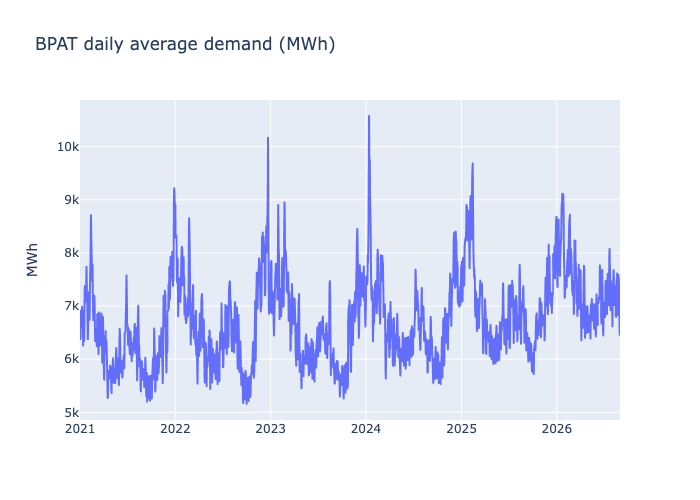

In [6]:
#daily average is easier to read than 49,000 hourly points
#use dataframe made above
daily = df.set_index("period_pacific")["demand_mwh"].resample("D").mean()

fig = px.line(daily, title="BPAT daily average demand (MWh)")
fig.update_layout(showlegend=False, yaxis_title="MWh", xaxis_title=None)
fig.show()

- `.resample("D").mean()` groups a time-indexed series into days and averages each one, the pandas version of `GROUP BY CAST(... AS DATE)`.

So we see that demand is growing as we a see slight trend over full date range using daily average. January–August averages rose from about 6,370 MWh in 2021 to about 7,350 in 2026 with the biggest jumps in 2025 and 2026. Peaks are maybe growing too (about 10,100 MWh in 2021 vs about 11,500 in 2024 and 2025) but 2025 and 2026 fell in comparison, did something happen then ore the years before at that time?.


Why does this matter -> it matters for modeling as a model trained on older years will tend to under-predict recent years since they are lower and over time it is increasing. 

So we should keep this in mind and look at:
- Split train/test by time where we train on earlier years but test on the most recent so the test mirrors real forecasting.
- Give the model a way to see the trend, maybe with a year or time-index feature and check whether errors drift upward over the test period.

## Daily cycle

Lets look at the daily cyle over the year, do how does demand look as the day changes

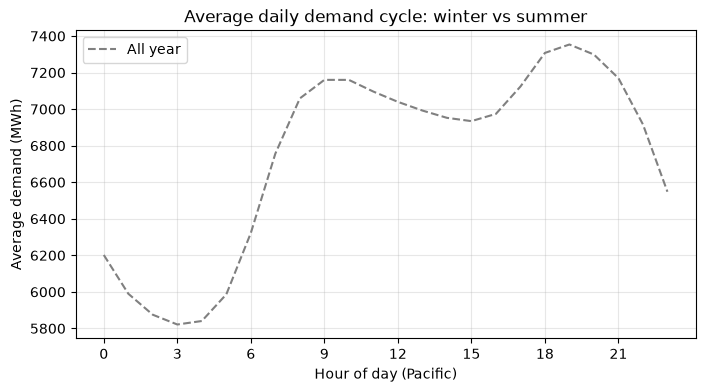

In [11]:
#average demand each hour for the year
fig, ax = plt.subplots(figsize=(8, 4))

all_year = df.groupby("hour_pacific")["demand_mwh"].mean()
ax.plot(all_year.index, all_year.values, color="gray", linestyle="--", label="All year")

ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Hour of day (Pacific)")
ax.set_ylabel("Average demand (MWh)")
ax.set_title("Average daily demand cycle: winter vs summer")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

So we see two peaks as the day goes on, the first is around 9 but start increasing at about 5 could be tied to waking up, the second is about 6-7 which could be tied to coming back home. It doesn't peak all day as we see a drop. Get general idea but..

### Season impact on hours of day

Time of year should impact so lets look at winter vs summer vs hours in a day this are the extremes/opposites and more consistent weather day to day so makes sense to check them where fall/spring are changing so it may be hot one day then cold the next so demand would have higher variability day to day. Or how the demand changes over a day in these two seasons

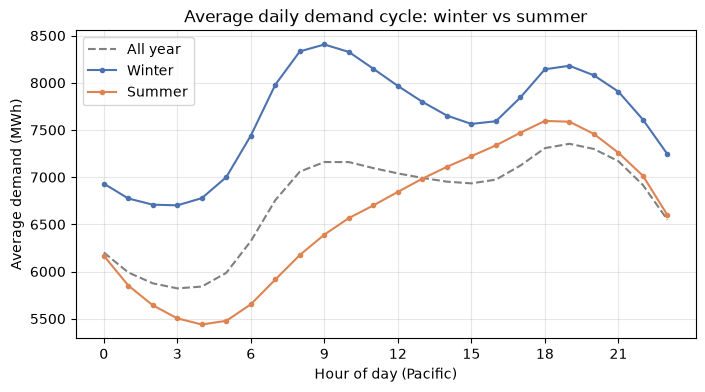

In [12]:
#average demand for each Pacific hour, winter vs summer
season_map = {12: "Winter", 1: "Winter", 2: "Winter", 6: "Summer", 7: "Summer", 8: "Summer"} # number corresponds to month then labeled time of year. 1 = January ->winter 

profile = (
    df.assign(season=df["month"].map(season_map))
      .dropna(subset=["season"])
      .groupby(["season", "hour_pacific"])["demand_mwh"]
      .mean()
      .unstack("season")
)

fig, ax = plt.subplots(figsize=(8, 4))

all_year = df.groupby("hour_pacific")["demand_mwh"].mean()
ax.plot(all_year.index, all_year.values, color="gray", linestyle="--", label="All year")

for season, color in [("Winter", "#4C72B0"), ("Summer", "#DD8452")]:
    ax.plot(profile.index, profile[season], marker="o", markersize=3, label=season, color=color)

ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Hour of day (Pacific)")
ax.set_ylabel("Average demand (MWh)")
ax.set_title("Average daily demand cycle: winter vs summer")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

So we see the all year trend is a combination of these two (fall and spring as well) as we can see the Winter double peak but it doesn't dip as far due to the summer climb and the overall is less than winter since summer has less demand than winter. 

Okay so what does summer to winter show us and what doe we see as the day goes on?   

- the two seasons have different shapes and different levels of demand
- `Winter` has two peaks with one in the morning around 8–9 am (about 8,400 MWh) as people wake up and heat homes and a second around 6–7 pm maybe people get back from work
- `Summer` has one peak and the demand builds through the afternoon to about 6–7 pm (about 7,600 MWh) as heat accumulates, and is lowest around 4 am 

taking this for the model then and hour of day alone isn't enough since the effect of the hour depends on the season

The pandas logic to make this plot is
1. `.assign(season=...)` adds a column
2. `.map(season_map)` looks each month up in the dictionary, and months not in it (spring, fall) become NaN
3. `.dropna(subset=["season"])` removes spring and fall for a clean winter vs summer comparison
4. `.groupby([...])["demand_mwh"].mean()` averages demand for each season-and-hour pair
5. `.unstack("season")` turns seasons into columns (one row per hour)
6. Then go through seasons and plot that column at each hour for a day

## Weekly cycle

Expand to a weekly cycle, seeing how the demand changes each day of the week. Is it more on a given day vs another? Good guess is to look at weekday vs weekend as those have different ideas about them so does it play a part

In [14]:
con.sql("""
    SELECT
        ISODOW(period_utc AT TIME ZONE 'America/Los_Angeles') AS day_of_week,
        DAYNAME(period_utc AT TIME ZONE 'America/Los_Angeles') AS day_name,
        ROUND(AVG(demand_mwh), 0) AS avg_mwh
    FROM model_hourly
    WHERE demand_mwh IS NOT NULL
    GROUP BY day_of_week, day_name
    ORDER BY day_of_week
""")

┌─────────────┬───────────┬─────────┐
│ day_of_week │ day_name  │ avg_mwh │
│    int64    │  varchar  │ double  │
├─────────────┼───────────┼─────────┤
│           1 │ Monday    │  6794.0 │
│           2 │ Tuesday   │  6884.0 │
│           3 │ Wednesday │  6885.0 │
│           4 │ Thursday  │  6876.0 │
│           5 │ Friday    │  6776.0 │
│           6 │ Saturday  │  6516.0 │
│           7 │ Sunday    │  6485.0 │
└─────────────┴───────────┴─────────┘

Per day of the week the averages are about the same with lower values on the weekends. Lets check that. Sort of agrees with orginal statement 

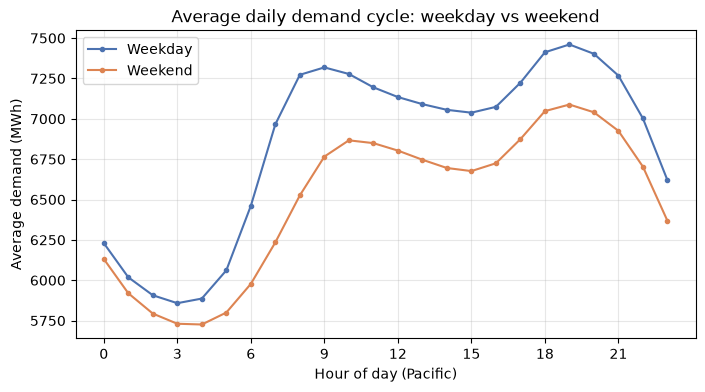

In [16]:
#weekday vs weekend daily cycle
week_profile = (
    df.assign(day_type=np.where(df["day_of_week"] >= 6, "Weekend", "Weekday"))
      .groupby(["day_type", "hour_pacific"])["demand_mwh"]
      .mean()
      .unstack("day_type")
)

fig, ax = plt.subplots(figsize=(8, 4))
for day_type, color in [("Weekday", "#4C72B0"), ("Weekend", "#DD8452")]:
    ax.plot(week_profile.index, week_profile[day_type], marker="o", markersize=3, label=day_type, color=color)

ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Hour of day (Pacific)")
ax.set_ylabel("Average demand (MWh)")
ax.set_title("Average daily demand cycle: weekday vs weekend")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

- `np.where(condition, a, b)` is a vectorized if/else: "Weekend" where `day_of_week >= 6`, otherwise "Weekday".

The trends for weeday vs weekend are the same but the weekend demand is lower overall. We see Tuesday–Thursday are highest (about 6,880 MWh), Monday and Friday a little lower, and weekends even lower (about 6,500). The plot shows where the gap is betwween the two as overnight demand is about the same then the difference opens up in the morning and through business hours. 
Weekend mornings also ramp up later.

### Holidays

Comparing holidays to all other days is misleading but want to see how they look. Most federal holidays fall in winter (New Year's, MLK Day, Presidents' Day, Thanksgiving, Christmas), when demand is high anyway. A fairer comparison is each holiday against the same weekday one week before and one week after, which keeps the season and day of week the same and looks more at how people/places are impacted

In [19]:
#daily average demand, by Pacific date
daily_avg = df.groupby(df["period_pacific"].dt.normalize())["demand_mwh"].mean()

holidays = USFederalHolidayCalendar().holidays(start="2021-01-01", end="2026-08-31") #pandas built in holiday calendar

rows = []
for h in holidays:
    week_before = h - pd.Timedelta(days=7)
    week_after  = h + pd.Timedelta(days=7)

    if h in daily_avg.index and week_before in daily_avg.index and week_after in daily_avg.index: #make sure we have points for all
        same_weekday = (daily_avg[week_before] + daily_avg[week_after]) / 2 #average of the day the week before and after
        rows.append({
            "date": h.date(),
            "holiday_mwh": round(daily_avg[h]),
            "same_weekday_mwh": round(same_weekday),
            "pct_diff": round(100 * (daily_avg[h] / same_weekday - 1), 1),
        })

holiday_check = pd.DataFrame(rows).sort_values("pct_diff")
holiday_check["pct_diff"].describe()

count    60.000000
mean     -1.943333
std       7.408181
min     -16.500000
25%      -6.025000
50%      -3.700000
75%       0.750000
max      28.700000
Name: pct_diff, dtype: float64

In [20]:
#biggest drops
holiday_check.head(10)

,date,holiday_mwh,same_weekday_mwh,pct_diff
20,2022-12-26,6854,8207,-16.5
15,2022-07-04,5885,6949,-15.3
19,2022-11-24,6898,7993,-13.7
4,2021-07-05,6266,6988,-10.3
30,2023-11-23,6868,7594,-9.6
23,2023-02-20,7029,7667,-8.3
48,2025-07-04,6256,6816,-8.2
53,2025-12-25,7523,8181,-8.0
27,2023-09-04,5542,6018,-7.9
40,2024-11-11,6565,7121,-7.8


How it is working:
- `USFederalHolidayCalendar` is built into pandas, so no extra package is needed. `.holidays()` returns the observed dates (e.g. when July 4 falls on a Saturday, the Friday before).
- `.dt.normalize()` sets every timestamp to midnight, turning hours into dates to group by.
- The `if` skips any holiday whose comparison weeks fall outside the data or on the dropped days.


Okay, so the typical holiday is a little bit lower than the same weekday nearby, and some barely differ at all. The biggest drops are Christmas, Thanksgiving and July 4 and are as large as a big weather swing. Other holidays sometimes drop about big as well (e.g. Presidents' Day 2023, Labor Day 2023), but less consistently. A few holidays even come out higher probably because of a cold snap or heat wave landed that week. So we should care at least about the consistent impacting holidays

**For the model:** a "major holiday" flag for the consistent ones (at least Christmas, Thanksgiving, July 4) is more useful than flagging every federal holiday. Look through the full `holiday_check` table to decide which others belong.

## Seasonality

We go through seasons each year so check how this impacts. Look at looks like each month to get a seasonal expectation, this needs to be months not days as seasons are over longer periods of time. Should expect and increase in winter then a decrease to summer and then increase again. 

In [21]:
con.sql("""
    SELECT
        MONTH(period_utc AT TIME ZONE 'America/Los_Angeles') AS month,
        MONTHNAME(period_utc AT TIME ZONE 'America/Los_Angeles') AS month_name,
        ROUND(AVG(demand_mwh), 0) AS avg_mwh,
        MAX(demand_mwh) AS peak_mwh
    FROM model_hourly
    WHERE demand_mwh IS NOT NULL
    GROUP BY month, month_name
    ORDER BY month
""").show(max_rows=12)

┌───────┬────────────┬─────────┬──────────┐
│ month │ month_name │ avg_mwh │ peak_mwh │
│ int64 │  varchar   │ double  │  double  │
├───────┼────────────┼─────────┼──────────┤
│     1 │ January    │  7700.0 │  11496.0 │
│     2 │ February   │  7557.0 │  11537.0 │
│     3 │ March      │  6871.0 │   9426.0 │
│     4 │ April      │  6409.0 │   9005.0 │
│     5 │ May        │  6183.0 │   7943.0 │
│     6 │ June       │  6407.0 │   9283.0 │
│     7 │ July       │  6745.0 │   9677.0 │
│     8 │ August     │  6586.0 │   9449.0 │
│     9 │ September  │  5872.0 │   8500.0 │
│    10 │ October    │  6004.0 │   8656.0 │
│    11 │ November   │  6909.0 │   9534.0 │
│    12 │ December   │  7624.0 │  11068.0 │
└───────┴────────────┴─────────┴──────────┘
  12 rows                       4 columns



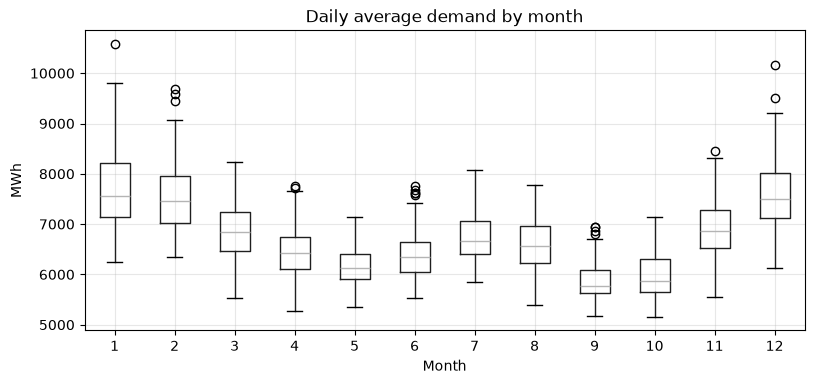

In [22]:
#spread of daily averages within each month
daily_df = daily.to_frame("demand_mwh")
daily_df["month"] = daily_df.index.month

fig, ax = plt.subplots(figsize=(9, 4))
daily_df.boxplot(column="demand_mwh", by="month", ax=ax, grid=False)
ax.set_title("Daily average demand by month")
ax.set_xlabel("Month")
ax.set_ylabel("MWh")
ax.grid(alpha=0.3)
plt.suptitle("") 
plt.show()

- The boxplot shows the spread as the box covers the middle 50% of days, the line is the median, and the dots are unusual days.

What this shows is that BPA is a winter-peaking system matching expecations. December–February average about 7,550–7,700 MWh September is lowest at about 5,900. There's a smaller summer bump in July.

Looking at the boxes matter to as we can see the winter months have the widest spread. A mild January day and an Arctic-outbreak January day can differ by thousands of MWh, so month alone can't predict winter demand since it varies and temperature has to do the work. May, September and October are the tightest and most predictable.

## Weather

Lets see how the weather comes into play

### Step 1 -> Straight-line correlation

In [ ]:
weather_cols = [c for c in df.columns if c.endswith(("_temp_f", "_feels_like_f", "_humidity_pct", "_wind_mph", "_cloud_pct", "_solar_wm2"))] #get weather columsn from data

df[["demand_mwh"] + weather_cols].corr()["demand_mwh"].drop("demand_mwh").sort_values()

kennewick_feels_like_f        -0.298715
everett_feels_like_f          -0.287325
kennewick_temp_f              -0.282311
everett_temp_f                -0.267185
vancouver_wash_feels_like_f   -0.263442
vancouver_wash_temp_f         -0.228045
everett_humidity_pct          -0.204049
eugene_feels_like_f           -0.203917
eugene_temp_f                 -0.167907
vancouver_wash_humidity_pct   -0.105676
eugene_humidity_pct           -0.094185
kennewick_wind_mph            -0.046617
everett_cloud_pct              0.021163
everett_wind_mph               0.037469
kennewick_solar_wm2            0.083472
vancouver_wash_solar_wm2       0.099397
eugene_solar_wm2               0.100336
everett_solar_wm2              0.103131
vancouver_wash_cloud_pct       0.106462
eugene_cloud_pct               0.120941
eugene_wind_mph                0.127617
vancouver_wash_wind_mph        0.128387
kennewick_humidity_pct         0.129659
kennewick_cloud_pct            0.178345
Name: demand_mwh, dtype: float64

- `.corr()` builds the full correlation table; `["demand_mwh"]` keeps just the column for demand, and `.drop("demand_mwh")` removes demand's correlation with itself (always 1).
- `str.endswith` accepts a tuple, so one call checks all six suffixes.

**What it shows:** every correlation is weak, with temperature only around -0.17 to -0.30 (min and max values). That looks like weather barely matters, but the demand-vs-temperature plot from before when we looked showed a clear V as we expected. 

What is happening, the Correlation only measures straight-line relationships so in a V, the cold side pushes the number negative and the hot side pushes it positive, so they cancel out so here the weak correlation doesn't necessarily mean weak relationship and we should check this more. 

### Step 2 -> Find the bottom of the V 

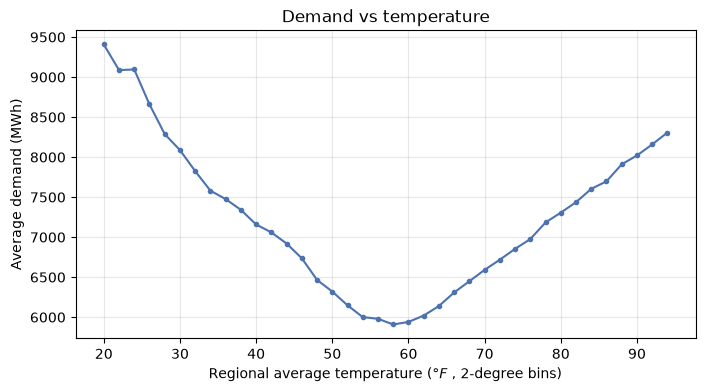

lowest demand at: 58.0 F


In [26]:
#average demand in 2 degree temperature bins
temp_bins = (
    df.assign(temp_bin=(df["temp_avg_f"] // 2) * 2)
      .groupby("temp_bin")["demand_mwh"]
      .agg(["mean", "count"])
)

temp_bins = temp_bins[temp_bins["count"] >= 50] #skip bins with too few hours to trust

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(temp_bins.index, temp_bins["mean"], marker="o", markersize=3, color="#4C72B0")
ax.set_xlabel(fr"Regional average temperature ($\degree F$ , 2-degree bins)")
ax.set_ylabel("Average demand (MWh)")
ax.set_title("Demand vs temperature")
ax.grid(alpha=0.3)
plt.show()

print("lowest demand at:", temp_bins["mean"].idxmin(), "F")

- `(x // 2) * 2` rounds down to the nearest even number, so 57.3 → 56. Each bin covers 2 °F.
- Bins with fewer than 50 hours are dropped, since an average of a handful of extreme hours is noisy.

**What it shows:** demand is lowest around 58–60 and climbs on both sides. The minimum is the temperature where buildings need neither heating nor cooling hence they balance and demand is low -> essentially the perfect temperature range for most. This is honeslty lower than I would have thought and would have guessed it to be closer to 65-70

Thist would have been smarter to plot first and made the correlation values easier to not misinterpret, which we did last notebook but again at the front is what I should have done. 

### Step 3 -> Heating and cooling degree-hours

The standard fix for a V shape is to split temperature into two one-sided features measured from the balance point:
- **Heating degree-hours (HDH)** = how far *below* 60 °F, or 0 if it's warmer
- **Cooling degree-hours (CDH)** = how far *above* 60 °F, or 0 if it's colder

Each one is a straight-ish line on its own side of the V.

In [28]:
BALANCE_F = 60 #point from above

degree_hours = pd.DataFrame({"demand_mwh": df["demand_mwh"]})

for loc in ["eugene", "everett", "kennewick", "vancouver_wash", "avg"]: #check every location

    temp = df[f"{loc}_temp_f"] if loc != "avg" else df["temp_avg_f"]
    
    degree_hours[f"{loc}_hdh"] = (BALANCE_F - temp).clip(lower=0)
    degree_hours[f"{loc}_cdh"] = (temp - BALANCE_F).clip(lower=0)

degree_hours.corr()["demand_mwh"].drop("demand_mwh").sort_values(ascending=False)

kennewick_hdh         0.525258
avg_hdh               0.476016
vancouver_wash_hdh    0.461909
everett_hdh           0.428336
eugene_hdh            0.371819
everett_cdh           0.168440
eugene_cdh            0.167893
vancouver_wash_cdh    0.150427
avg_cdh               0.145998
kennewick_cdh         0.045053
Name: demand_mwh, dtype: float64

- `.clip(lower=0)` replaces negatives with 0, which is what makes each feature one-sided.

From these values we get 
- Heating degree-hours correlate about 0.37–0.53 roughly double plain temperature from before so showing same data with different outcomes
- Kennewick is the best heating signal with 0.53 even better than all of the cities averaged which was 0.48 (2nd best). So going east would seem to mean its colder and need more heat. Kennewick is the weakest cooling signal so maybe cooler east. However we saw kennewick gets hot before when looking at temperatures so maybe a more consistent hot so demand doesn't change much?
- Cooling degree-hours are weaker overall and are about 0.05–0.17. So maybe heat matters less but we see the dependence in the temperature plot. What could cause this?  maybe because there fewer hours that are hot than cold, so cooling moves an all-hours correlation much less or less temperature above the balance than below.
- 
- No single location is best for both sides.

**For the model:** we should give it heating and cooling degree-hours per location and let it learn the weights, rather than one regional average since they have different dependences

## Time alignment: does demand react to recent weather?


It takes time for things to hear/cool So after a cold night we may need extra heating in the morning even if it has warmed up.
So demand may track the last several hours of temperature better than the current hour as the change takes affect.

This uses the full hourly table. Shifting by hours only works if every hour is present but we need to be careful since on `df` we have gaps so a shift of 1 could jump across a missing day.

In [29]:
#get hourly values from table
hourly = con.sql("""
    SELECT
        period_utc,
        demand_mwh,
        (eugene_temp_f + everett_temp_f + kennewick_temp_f + vancouver_wash_temp_f) / 4 AS temp_avg_f
    FROM model_hourly
    ORDER BY period_utc
""").df()

#get the hdh from here as before it is balance - temp 
hdh = (BALANCE_F - hourly["temp_avg_f"]).clip(lower=0)

#temperature from k hours earlier
#here is the last couple hours not the hour 
lag_check = pd.DataFrame({
    "hours_earlier": range(0, 7), #can adjust if desired but up to 7 here
    "corr": [hourly["demand_mwh"].corr(hdh.shift(k)) for k in range(0, 7)], #checks corr for each hour earlier up to 7
})

#average temperature over the last w hours
rolling_check = pd.DataFrame({
    "window_hours": [1, 3, 6, 12, 24, 48, 72],
    "corr": [hourly["demand_mwh"].corr((BALANCE_F - hourly["temp_avg_f"].rolling(w).mean()).clip(lower=0))
             for w in [1, 3, 6, 12, 24, 48, 72]],
})

display(lag_check.round(3), rolling_check.round(3))

,hours_earlier,corr
0,0,0.476
1,1,0.494
2,2,0.508
3,3,0.519
4,4,0.528
5,5,0.537
6,6,0.548


,window_hours,corr
0,1,0.476
1,3,0.496
2,6,0.521
3,12,0.579
4,24,0.572
5,48,0.562
6,72,0.552


How it is setup is
- `.shift(k)` moves a column down by `k` rows, so each hour lines up with the temperature from `k` hours earlier.
- `.rolling(w).mean()` averages the current hour and the `w - 1` before it.
- `.corr()` skips any pair with a NaN, so the dropped days and the first few rows are left out automatically.

Then from the table we get that 
- Correlation keeps rising the further back the temperature goes for the hours check as at about 0.48 for the current hour the about 0.55 for 6 hours earlier.
- This isn't try for the rolling window so there is some cut. We see that a 12-hour rolling average is best at about 0.58 and longer windows are close behind.
- These show demand depends on how long just not right now and the rolling suggest at least up to half a day of time

to consider for the model we should add rolling-average temperatures alongside the current hour. Rolling since it was highest at 12 hours which is likely the one we should consider

## Benchmark: how good is EIA's day-ahead forecast?

Okay so we have done some exploring and seen how demand looks over a day at different times of the year, how it looks over seasons, how weather impacts it, holiday days, the day of the week, and now it is time to try look at how good the EIA gorecast they give is. 

`eia_forecast_mwh` is the forecast published for each hour a day ahead. Whatever model gets built has to be compared against it.

Error measures used:
- **MAE** (mean absolute error): average size of the miss in MWh.
- **MAPE** (mean absolute percentage error): average miss as a % of actual demand
- **RMSE** (root mean squared error): like MAE, but big misses count extra.
- **Bias**: average of (forecast − actual). Positive means over-forecasting on average.

In [30]:
#pull from the table made
#get hours then the average between actual and forcast and all other stated errors above 

con.sql("""
    SELECT
        COUNT(*) AS n_hours,
        ROUND(AVG(ABS(eia_forecast_mwh - demand_mwh)), 0) AS mae_mwh, --MAE
        ROUND(100 * AVG(ABS(eia_forecast_mwh - demand_mwh) / demand_mwh), 2) AS mape_pct, --MAPE
        ROUND(SQRT(AVG(POWER(eia_forecast_mwh - demand_mwh, 2))), 0) AS rmse_mwh, --RMSE
        ROUND(AVG(eia_forecast_mwh - demand_mwh), 0) AS bias_mwh --Bias
    FROM model_hourly
    WHERE demand_mwh IS NOT NULL
      AND eia_forecast_mwh IS NOT NULL --make sure get non null
      AND YEAR(period_utc AT TIME ZONE 'America/Los_Angeles') >= 2021 --remove 2020 part again
""")

┌─────────┬─────────┬──────────┬──────────┬──────────┐
│ n_hours │ mae_mwh │ mape_pct │ rmse_mwh │ bias_mwh │
│  int64  │ double  │  double  │  double  │  double  │
├─────────┼─────────┼──────────┼──────────┼──────────┤
│   49528 │   137.0 │     2.01 │    182.0 │      8.0 │
└─────────┴─────────┴──────────┴──────────┴──────────┘

- `WHERE ... IS NOT NULL` on both columns applies a comparison only on hours where both a forecast and a real demand value exist
- `POWER(x, 2)` squares the error; `SQRT(AVG(...))` takes the square root of the average squared error.

So mae and rmse are a little different so they are some large misses and we see that we overforcast on average. 

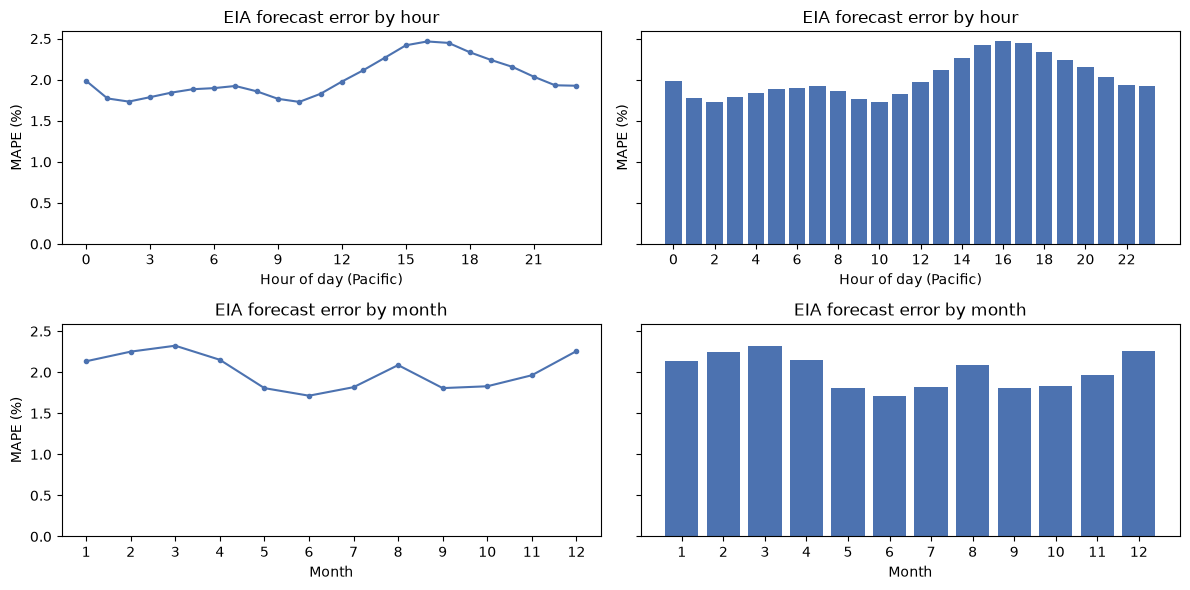

In [35]:
#where does EIA miss most 
# this is done by hour of day and by month

#get benchmark values to check
bench = df.dropna(subset=["eia_forecast_mwh"]).copy() #the benchmark
bench["ape_pct"] = 100 * (bench["eia_forecast_mwh"] - bench["demand_mwh"]).abs() / bench["demand_mwh"] #abslute percent error 

#groupings
by_hour = bench.groupby("hour_pacific")["ape_pct"].mean()
by_month = bench.groupby("month")["ape_pct"].mean()

#plot
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharey=True)

axes[0,0].plot(by_hour.index, by_hour.values, marker="o", markersize=3, color="#4C72B0")
axes[0,0].set_xticks(range(0, 24, 3))
axes[0,0].set_xlabel("Hour of day (Pacific)")
axes[0,0].set_ylabel("MAPE (%)")
axes[0,0].set_title("EIA forecast error by hour")

axes[0,1].bar(by_hour.index, by_hour.values, color="#4C72B0")
axes[0,1].set_xticks(range(0, 24, 2))
axes[0,1].set_xlabel("Hour of day (Pacific)")
axes[0,1].set_ylabel("MAPE (%)")
axes[0,1].set_title("EIA forecast error by hour")

axes[1,0].plot(by_month.index, by_month.values, marker="o", markersize=3, color="#4C72B0")
axes[1,0].set_xticks(range(1, 13))
axes[1,0].set_xlabel("Month")
axes[1,0].set_ylabel("MAPE (%)")
axes[1,0].set_title("EIA forecast error by month")

axes[1,1].bar(by_month.index, by_month.values, color="#4C72B0")
axes[1,1].set_xticks(range(1, 13))
axes[1,1].set_xlabel("Month")
axes[1,1].set_title("EIA forecast error by month")

plt.tight_layout()
plt.show()

By hour: 
- There is a peak as error increase at 4-6, around time we saw peaks for winter/summer and weekdays as well

By month:
- follows what we saw in box plot. Less error in september and october and more during winter months

In [41]:
#exact numbers behind the month chart, plus the direction of the error
by_month_table = bench.groupby("month").agg(
    mape_pct=("ape_pct", "mean"),
    bias_mwh=("eia_forecast_mwh", lambda f: (f - bench.loc[f.index, "demand_mwh"]).mean()),
).round(2)

by_month_table

,mape_pct,bias_mwh
month,,
1,2.13,-6.99
2,2.25,-1.85
3,2.32,-15.40
4,2.15,-41.13
5,1.81,16.10
6,1.71,25.66
7,1.82,33.24
8,2.09,49.06
9,1.81,31.24


In [36]:
#worst days
con.sql("""
    SELECT
        CAST(period_utc AT TIME ZONE 'America/Los_Angeles' AS DATE)  AS date_pacific,
        ROUND(100 * AVG(ABS(eia_forecast_mwh - demand_mwh) / demand_mwh), 1) AS mape_pct,
        ROUND(AVG(eia_forecast_mwh - demand_mwh), 0)                 AS bias_mwh,
        ROUND(AVG((eugene_temp_f + everett_temp_f + kennewick_temp_f + vancouver_wash_temp_f) / 4), 1) AS temp_avg_f
    FROM model_hourly
    WHERE demand_mwh IS NOT NULL AND eia_forecast_mwh IS NOT NULL
    GROUP BY date_pacific
    ORDER BY mape_pct DESC
    LIMIT 10
""")

┌──────────────┬──────────┬──────────┬────────────┐
│ date_pacific │ mape_pct │ bias_mwh │ temp_avg_f │
│     date     │  double  │  double  │   double   │
├──────────────┼──────────┼──────────┼────────────┤
│ 2026-04-06   │      7.3 │   -493.0 │       58.2 │
│ 2024-10-26   │      6.9 │    411.0 │       56.1 │
│ 2021-03-28   │      6.7 │   -431.0 │       46.6 │
│ 2026-08-05   │      6.7 │    499.0 │       74.1 │
│ 2025-08-25   │      6.7 │    501.0 │       78.0 │
│ 2023-03-11   │      6.5 │    438.0 │       42.2 │
│ 2023-01-05   │      6.4 │    460.0 │       45.0 │
│ 2024-01-07   │      6.2 │    463.0 │       36.6 │
│ 2026-01-06   │      6.2 │   -523.0 │       41.8 │
│ 2023-04-20   │      6.2 │   -448.0 │       43.2 │
└──────────────┴──────────┴──────────┴────────────┘
  10 rows                               4 columns

In [40]:
#EIA's accuracy stable over time
con.sql("""
    SELECT
        YEAR(period_utc AT TIME ZONE 'America/Los_Angeles') AS year,
        COUNT(*) AS n_hours,
        ROUND(100 * AVG(ABS(eia_forecast_mwh - demand_mwh) / demand_mwh), 2) AS mape_pct,
        ROUND(AVG(eia_forecast_mwh - demand_mwh), 0) AS bias_mwh
    FROM model_hourly
    WHERE demand_mwh IS NOT NULL
      AND eia_forecast_mwh IS NOT NULL
      AND YEAR(period_utc AT TIME ZONE 'America/Los_Angeles') >= 2021
    GROUP BY year
    ORDER BY year
""")

┌───────┬─────────┬──────────┬──────────┐
│ year  │ n_hours │ mape_pct │ bias_mwh │
│ int64 │  int64  │  double  │  double  │
├───────┼─────────┼──────────┼──────────┤
│  2021 │    8712 │     2.08 │     27.0 │
│  2022 │    8760 │     2.09 │     26.0 │
│  2023 │    8712 │     2.04 │     -2.0 │
│  2024 │    8784 │     1.97 │    -18.0 │
│  2025 │    8760 │     2.01 │     15.0 │
│  2026 │    5800 │     1.84 │     -5.0 │
└───────┴─────────┴──────────┴──────────┘

Overall 
- **EIA's forecast is very good: about 2.0% MAPE** (about 137 MWh average miss, RMSE about 182), with almost no bias (+8 MWh). It has been consistent every year (about 1.8–2.1%).
- **Worst in the afternoon** (3–5 pm, about 2.4–2.5%) and best overnight and late morning (about 1.7%).
- **Worst in winter and early spring** (Dec–Apr, about 2.1–2.3%) and **August** (about 2.1%), best in May–June (about 1.7–1.8%). Late summer (Jul–Sep) has a small over-forecast bias of about 30–50 MWh.
- **Worst days** miss by about 6–7% on average, roughly 400–500 MWh off across the whole day, in both directions. They're spread across the year and are mostly *not* the most extreme days (average temperatures 37–78 °F): the hard days for EIA are likely ones where the weather turned out differently than forecast, not simply the coldest or hottest ones.


## Summary

| Finding | Evidence | Feature for the model |
|---|---|---|
| Demand is growing | Jan–Aug average up ~15% from 2021 to 2026 | Time trend; **split train/test by time** |
| Daily shape differs by season | Winter: morning + evening peaks; summer: one late-afternoon peak | Hour of day + month/season (trees learn the interaction) |
| Weekends lower | ~5% lower, mostly during business hours | Day of week / weekend flag |
| Major holidays much lower | Christmas, Thanksgiving, July 4: about −8 to −17% vs same weekday | "Major holiday" flag |
| Winter-peaking, most spread in winter | Dec–Jan avg ~7,600–7,700 MWh, peaks >11,000 | Month; weather does the heavy lifting in winter |
| V-shaped temperature response | Lowest demand at ~58–60 °F | Heating and cooling degree-hours (base 60 °F) |
| Locations differ | Kennewick best for heating, worst for cooling | Degree-hours **per location** |
| Demand reacts to recent weather | 12 h rolling average beats current temperature | Rolling temperature (12 h, 24 h) |

**Benchmark to beat:** EIA day-ahead forecast, **~2.0% MAPE / ~137 MWh MAE / ~182 MWh RMSE**, weakest in winter–spring afternoons

In [42]:
con.close()